[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/udayRage/streamPAMI/blob/main/notebooks/frequentPattern/basic/FPStream.ipynb)

# Finding frequent itemsets in transaction streams with FPStream

This tutorial follows PAMI's progression: mine once, evaluate several support
thresholds, then feed batches as a live stream. Pattern supports are counts;
minSup is a fraction, unlike PAMI's optional absolute-count threshold.

[Algorithm documentation and accuracy limits](../../../docs/frequentPattern/basic/FPStream.md)

Locally, install the notebook tools in your virtual environment with
`pip install -e ".[notebooks]"` from the repository root, then select that
environment's Python kernel. Colab already supplies a notebook environment.


## Prerequisites

### Install only if needed

Keep an existing local installation, including an editable checkout. The
conditional installation below runs only if streamPAMI cannot be imported.


In [1]:
try:
    import streamPAMI
except ImportError:
    %pip install -q git+https://github.com/udayRage/streamPAMI


### Download a sample dataset

Use T10I4D100K, also used in the project's evaluation. Python's downloader
works on Windows and Colab. An existing local file is reused.


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_path = Path("Transactional_T10I4D100K.csv")
data_url = "https://u-aizu.ac.jp/~udayrage/datasets/transactionalDatabases/Transactional_T10I4D100K.csv"
if not data_path.is_file():
    urlretrieve(data_url, data_path)
print("Dataset:", data_path.name)


Dataset: Transactional_T10I4D100K.csv


### Inspect the input

Each non-blank line is a transaction containing tab-separated item labels.
There is no header or transaction id. Blank file lines are skipped. The
filename is a dataset label; use the actual non-blank transaction count.


In [3]:
from itertools import islice

with data_path.open(encoding="utf-8") as source:
    for line in islice(source, 2):
        print(line.rstrip("\r\n"))
with data_path.open(encoding="utf-8") as source:
    transaction_count = sum(bool(line.strip()) for line in source)
print("Transactions:", transaction_count)


25	52	164	240	274	328	368	448	538	561	630	687	730	775	825	834
39	120	124	205	401	581	704	814	825	834
Transactions: 99935


## Part 1: Mining once

### Step 1: Choose parameters

Choose minSup = 0.006, epsilon = 0.0006 and batchSize = 10,000.
Here epsilon is one tenth of minSup, so minSup > 2*epsilon holds.
Queries below cover the whole stream, starting at the newest frame.
Older-only periods have a known limitation with uneven batch sizes.


In [4]:
from streamPAMI.frequentPattern.basic.FPStream import FPStream

batch_size = 10000
min_sup = 0.006
epsilon = 0.0006
miner = FPStream(data_path, min_sup, epsilon, batch_size)


### Step 2: Mine, print and save

The stored answer covers the whole input stream. Its counts are estimates.

The saved format is `item1<tab>item2:support`.


In [5]:
miner.mine()
miner.printResults()
output_path = Path("FPStream_patterns.txt")
miner.save(output_path)


Total number of patterns: 935
Total time taken: 27.604209000011906
Total memory in USS: 141725696
Total memory in RSS: 168267776


In [6]:
print("First saved pattern lines:")
with output_path.open(encoding="utf-8") as source:
    for line in islice(source, 5):
        print(line.rstrip("\r\n"))


First saved pattern lines:
0:594
1:1532
10:1349
100:1748
104:1158


In [7]:
miner.getPatternsAsDataFrame().head()


,Patterns,Support
0,0,594
1,1,1532
2,10,1349
3,100,1748
4,104,1158


## Part 2: Evaluating different minSup values

### Step 1: Choose thresholds and result columns

Rebuild and replay for each threshold; none of these miners accepts a
minSup argument at query time. Runtime is from mine(), including its final
query. RSS is the captured process memory reading in decimal MB, not a peak.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
min_sups = [0.006, 0.007, 0.008, 0.009, 0.010]
rows = []


### Step 2: Execute and print the results

Epsilon is 0.1 * minSup on each run.


In [9]:
for threshold in min_sups:
    candidate = FPStream(data_path, threshold, 0.1 * threshold, batch_size)
    candidate.mine()
    rows.append({"algorithm": "FPStream", "minSup": threshold,
                 "patterns": len(candidate.getPatterns()),
                 "runtime_s": candidate.getRuntime(),
                 "memory_mb": candidate.getMemoryRSS() / 1000000})
results = pd.DataFrame(rows)
print(results.to_string(index=False))


algorithm  minSup  patterns  runtime_s  memory_mb
 FPStream   0.006       935  25.542755 216.662016
 FPStream   0.007       707  21.996435 214.499328
 FPStream   0.008       583  20.320692 213.094400
 FPStream   0.009       479  18.747849 211.419136
 FPStream   0.010       421  16.281528 211.726336


### Step 3: Visualise the results

These numbers come from sequential runs in one process and are for
illustration. They include process state retained from earlier cells.
Fair measurements are in [benchmarks/](../../../benchmarks/README.md) and
the [README Evaluation section](../../../README.md#evaluation), which
currently compare FP-Stream and DSTree with an exact baseline.


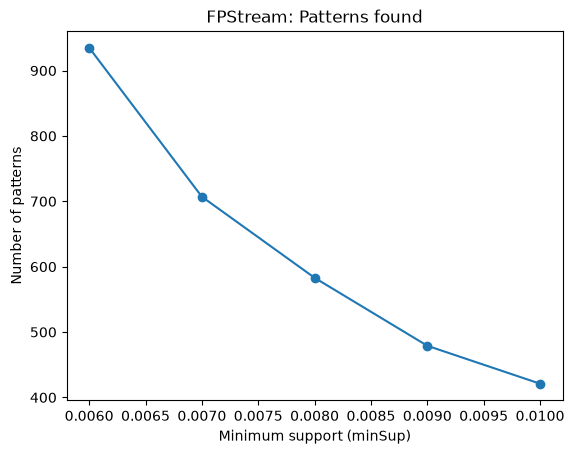

In [10]:
axis = results.plot(x="minSup", y="patterns", marker="o", legend=False,
                    title="FPStream: Patterns found")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Number of patterns")
plt.show()


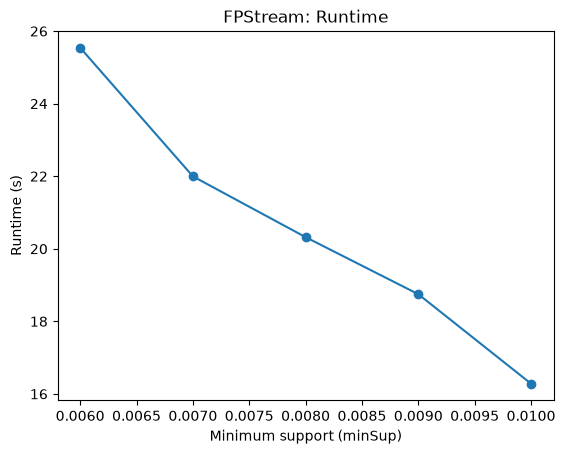

In [11]:
axis = results.plot(x="minSup", y="runtime_s", marker="o", legend=False,
                    title="FPStream: Runtime")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Runtime (s)")
plt.show()


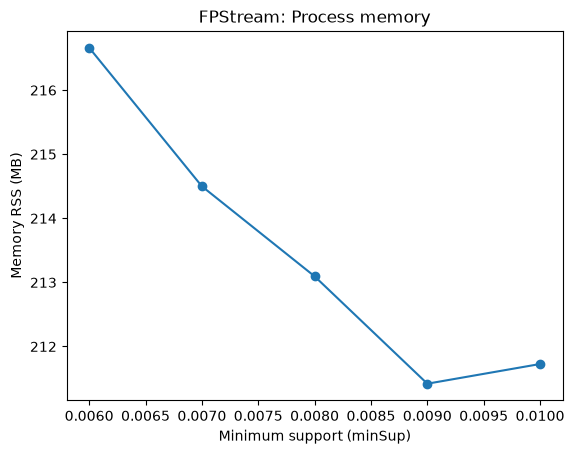

In [12]:
axis = results.plot(x="minSup", y="memory_mb", marker="o", legend=False,
                    title="FPStream: Process memory")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Memory RSS (MB)")
plt.show()


## Part 3: Using it as a live stream

Feed the first six full batches. The printed processing time measures only
processBatch(); the following query is outside that timer. queryPatterns()
returns the current answer; getPatterns() remains the last mine() result.


In [13]:
from time import perf_counter

def read_batches(path, size):
    batch = []
    with path.open(encoding="utf-8") as source:
        for line in source:
            line = line.strip()
            if not line:
                continue
            batch.append(line.split("\t"))
            if len(batch) == size:
                yield batch
                batch = []
    if batch:
        yield batch


In [14]:
live = FPStream(None, min_sup, epsilon, batch_size)
for batch_number, batch in enumerate(islice(read_batches(data_path, batch_size), 6), start=1):
    started = perf_counter()
    live.processBatch(batch)
    processing_s = perf_counter() - started
    patterns = live.queryPatterns()
    print(f"Batch {batch_number}: patterns={len(patterns)}, processing_s={processing_s:.6f}")
    print("Frames:", live.getTimeFrames())
    print("Frame weights:", live.getFrameWeights())


Batch 1: patterns=1040, processing_s=1.258607
Frames: [(0, 1)]
Frame weights: [10000]


Batch 2: patterns=931, processing_s=1.931716
Frames: [(1, 2), (0, 1)]
Frame weights: [10000, 10000]


Batch 3: patterns=938, processing_s=1.954823
Frames: [(2, 3), (0, 2)]
Frame weights: [10000, 20000]


Batch 4: patterns=950, processing_s=2.198992
Frames: [(3, 4), (2, 3), (0, 2)]
Frame weights: [10000, 10000, 20000]


Batch 5: patterns=929, processing_s=2.313486
Frames: [(4, 5), (2, 4), (0, 2)]
Frame weights: [10000, 20000, 20000]


Batch 6: patterns=924, processing_s=2.773758
Frames: [(5, 6), (4, 5), (2, 4), (0, 2)]
Frame weights: [10000, 10000, 20000, 20000]


Compare the newest frame with the whole stream. The dictionaries contain counts; the samples below show only their first few sorted entries.


In [15]:
newest = live.queryPatterns(0, 1)
whole = live.queryPatterns()
print("Newest frame patterns:", len(newest))
print("Newest frame sample:", sorted(newest.items())[:5])
print("Whole stream patterns:", len(whole))
print("Whole stream sample:", sorted(whole.items())[:5])


Newest frame patterns: 1150
Newest frame sample: [(('1',), 157), (('10',), 127), (('100',), 167), (('100', '362'), 55), (('104',), 101)]
Whole stream patterns: 924
Whole stream sample: [(('0',), 344), (('1',), 919), (('10',), 786), (('100',), 1072), (('100', '362'), 363)]


The frame list is newest first, with end-exclusive batch boundaries.
Older frames merge as history grows. Both queries above start at the
newest frame; that condition and minSup > 2*epsilon are required for
the guarantee. Do not assume the same guarantee for older-only ranges.


In a real stream, append each broker message's transaction to the current
batch. Call processBatch when the batch is full, query when needed, then
start the next batch. Choose batch and query rates for the application's
latency and memory needs.
